# 🚀 Модуль 12. Урок 2. LangChain и LlamaIndex для аналитики: структурирование знаний

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_12_ai_agents/lesson_02_langchain_llamaindex_for_analytics.ipynb)

## 📌 Бизнес-контекст и методология
Фреймворки LangChain и LlamaIndex предоставляют готовые кирпичики для сборки корпоративных агентов:
- Загрузчики данных из SQL, CSV, Google Sheets
- Управление историей диалога (Conversation Memory)
- Индексация табличных структур
Однако в 2027 году аналитики переходят на легковесные нативные SDK (Anthropic Tool Use / OpenAI Swarm), избегая избыточных абстракций.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

## 🔍 Разбор механики: Расход памяти и токенов в многошаговых сессиях
Сравним рост расхода контекста при различных стратегиях управления памятью агента.

In [2]:
# Демонстрация: Динамика роста токенов в памяти агента
turns = np.arange(1, 11)
tokens_full_history = turns * 1800
tokens_summary_memory = np.where(turns <= 3, turns * 1800, 3 * 1800 + (turns - 3) * 450)

memory_df = pd.DataFrame({
    'Ход диалога': turns,
    'Полная история (Full History)': tokens_full_history,
    'Сжатая память (Summary Memory)': tokens_summary_memory
})
display(memory_df.tail(4))

,Ход диалога,Полная история (Full History),Сжатая память (Summary Memory)
6,7,12600,7200
7,8,14400,7650
8,9,16200,8100
9,10,18000,8550


## 📊 Визуализация бизнес-кейса: Оптимизация контекстного окна агента
Построим сравнение потребления токенов при росте длины диалога.

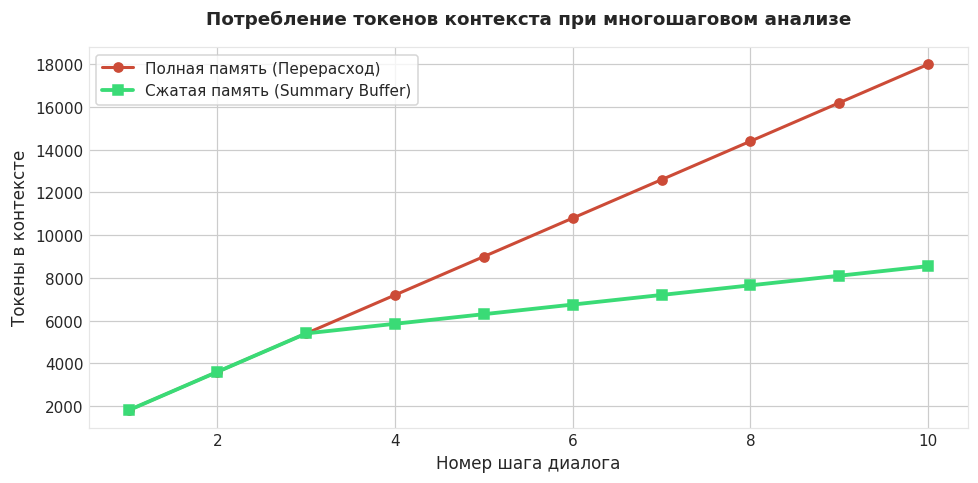

In [3]:
# Визуализация потребления памяти
fig, ax = plt.subplots(figsize=(9, 4.5), dpi=110)

ax.plot(turns, memory_df['Полная история (Full History)'], marker='o', color=ALERT, linewidth=2, label='Полная память (Перерасход)')
ax.plot(turns, memory_df['Сжатая память (Summary Memory)'], marker='s', color=SUCCESS, linewidth=2.5, label='Сжатая память (Summary Buffer)')

ax.set_title("Потребление токенов контекста при многошаговом анализе", fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel("Номер шага диалога", fontsize=11)
ax.set_ylabel("Токены в контексте", fontsize=11)
ax.legend(frameon=True, facecolor='#ffffff')

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Экономия токенов на 10-м ходе
Посчитайте разницу в токенах между полной историей и сжатой памятью на 10-м ходе.

In [4]:
### ВАШ КОД ЗДЕСЬ
diff_tokens = memory_df.loc[9, 'Полная история (Full History)'] - memory_df.loc[9, 'Сжатая память (Summary Memory)']
print(f"Сэкономлено токенов на 10-м шаге: {diff_tokens:,}")

assert diff_tokens > 9000, "Экономия должна превышать 9000 токенов"
print("✅ Тест успешно пройден: сжатие памяти предотвращает переполнение контекста!")

Сэкономлено токенов на 10-м шаге: 9,450
✅ Тест успешно пройден: сжатие памяти предотвращает переполнение контекста!


### 💡 Стратегия Memory Pruning
Сбрасывайте сырые SQL-выборки из памяти агента после формирования итогового ответа. Храните в долгосрочной памяти только агрегированные цифры и финальные выводы.